# 1. Data Acquisition
Duyệt danh sách bệnh nhân trên PhysioNet, chọn cohort, đọc numerics record.

## 1.0 Import & cấu hình

In [1]:
import wfdb
import pandas as pd
import numpy as np
import requests
import random

DB_NAME = "mimic3wdb-matched"
DB_VERSION = "1.0"
RECORDS_URL = f"https://physionet.org/files/{DB_NAME}/{DB_VERSION}/RECORDS-numerics"

random.seed(42)  

## 1.1 Lấy danh sách toàn bộ numerics record từ PhysioNet

In [2]:
def fetch_records_list(url: str) -> list[str]:
    """Tải file RECORDS-numerics, trả về list đường dẫn record (mỗi dòng 1 record)."""
    resp = requests.get(url, timeout=30)
    resp.raise_for_status()
    lines = resp.text.strip().splitlines()
    return lines

record_paths = fetch_records_list(RECORDS_URL)
print(f"Tổng số numerics record: {len(record_paths)}")
print("Ví dụ 3 dòng đầu:", record_paths[:3])

Tổng số numerics record: 22247
Ví dụ 3 dòng đầu: ['p00/p000020/p000020-2183-04-28-17-47n', 'p00/p000030/p000030-2172-10-16-12-22n', 'p00/p000033/p000033-2116-12-24-12-35n']


In [3]:
def group_by_patient(record_paths: list[str]) -> dict[str, list[str]]:
    """
    Mỗi record_path dạng: p04/p044083/p044083-2112-05-04-19-50n
    -> gom theo patient_id (p044083) để biết bệnh nhân nào có bao nhiêu record.
    """
    patients = {}
    for path in record_paths:
        parts = path.split("/")
        patient_id = parts[1]  # ví dụ: p044083
        patients.setdefault(patient_id, []).append(path)
    return patients

patients_dict = group_by_patient(record_paths)
print(f"Tổng số bệnh nhân (unique): {len(patients_dict)}")

Tổng số bệnh nhân (unique): 10269


## 1.2 Sàng lọc nhanh & chọn cohort (~50-70 bệnh nhân)

In [4]:
def screen_candidate(patient_id: str, record_path: str, window_minutes: int = 30, skip_minutes: int = 15) -> dict | None:
    """
    Đọc header (nhẹ) + 1 cửa sổ ngắn để lấy proxy SpO2/PULSE/RESP.
    Bỏ qua `skip_minutes` đầu tiên để tránh giai đoạn gắn cảm biến chưa ổn định.
    Trả về None nếu record không có đủ tín hiệu, hoặc cửa sổ vẫn toàn dropout.
    """
    pn_dir = f"{DB_NAME}/{DB_VERSION}/" + "/".join(record_path.split("/")[:-1])
    record_name = record_path.split("/")[-1]

    try:
        header = wfdb.rdheader(record_name, pn_dir=pn_dir)
    except Exception:
        return None

    sig_names = [s.upper() for s in header.sig_name]
    if "SPO2" not in sig_names or "PULSE" not in sig_names:
        return None

    sampfrom = int(skip_minutes * 60 * header.fs)
    sampto = int((skip_minutes + window_minutes) * 60 * header.fs)

    if sampto > header.sig_len:
        sampfrom, sampto = 0, min(window_minutes * 60 * header.fs, header.sig_len)

    try:
        rec = wfdb.rdrecord(record_name, pn_dir=pn_dir, sampfrom=sampfrom, sampto=sampto)
    except Exception:
        return None

    df = pd.DataFrame(rec.p_signal, columns=[s.upper() for s in rec.sig_name])
    spo2_clean = df["SPO2"].replace(0, np.nan)
    pulse_clean = df["PULSE"].replace(0, np.nan)

    if spo2_clean.isna().all() or pulse_clean.isna().all():
        return None  

    return {
        "patient_id": patient_id,
        "record_path": record_path,
        "spo2_mean_proxy": spo2_clean.mean(),
        "pulse_mean_proxy": pulse_clean.mean(),
        "dropout_ratio_spo2": spo2_clean.isna().mean(),  
        "has_resp_signal": "RESP" in sig_names,
    }

In [5]:
# Bước 1: lấy pool ứng viên lớn hơn nhu cầu thật 
candidate_pool_size = 500
candidate_patients = random.sample(list(patients_dict.keys()), candidate_pool_size)

# Bước 2: sàng lọc từng ứng viên 
screening_results = []
for pid in candidate_patients:
    first_record = patients_dict[pid][0]
    result = screen_candidate(pid, first_record)
    if result is not None:
        screening_results.append(result)

screening_df = pd.DataFrame(screening_results)
print(f"Ứng viên hợp lệ sau sàng lọc: {len(screening_df)} / {candidate_pool_size}")
screening_df.head()

Ứng viên hợp lệ sau sàng lọc: 122 / 500


,patient_id,record_path,spo2_mean_proxy,pulse_mean_proxy,dropout_ratio_spo2,has_resp_signal
0,p030669,p03/p030669/p030669-2116-02-20-12-33n,100.000000,69.991556,0.000,True
1,p018852,p01/p018852/p018852-2122-09-22-18-04n,100.000000,66.396667,0.000,True
2,p013739,p01/p013739/p013739-2110-02-19-15-51n,93.530000,84.993333,0.000,True
3,p011694,p01/p011694/p011694-2101-03-16-19-56n,96.390000,82.550000,0.000,True
4,p094312,p09/p094312/p094312-2143-04-03-20-19n,99.474474,63.551952,0.075,True


In [6]:
# Bước 3: loại bỏ dropout quá cao trước khi ưu tiên theo SpO2 thấp
MAX_DROPOUT_RATIO = 0.20  
FINAL_COHORT_SIZE = 75

quality_filtered_df = screening_df[screening_df["dropout_ratio_spo2"] <= MAX_DROPOUT_RATIO]
print(f"Còn lại sau lọc dropout: {len(quality_filtered_df)} / {len(screening_df)}")

cohort_df = (
    quality_filtered_df
    .sort_values("spo2_mean_proxy", ascending=True)
    .head(FINAL_COHORT_SIZE)
    .reset_index(drop=True)
)
cohort_df

Còn lại sau lọc dropout: 108 / 122


,patient_id,record_path,spo2_mean_proxy,pulse_mean_proxy,dropout_ratio_spo2,has_resp_signal
0,p021265,p02/p021265/p021265-2152-07-15-16-06n,86.896552,79.537931,0.033333,True
1,p062248,p06/p062248/p062248-2101-05-08-01-38n,90.624444,83.160000,0.000000,True
2,p052172,p05/p052172/p052172-2106-11-26-14-31n,91.325556,91.183889,0.000000,True
3,p007651,p00/p007651/p007651-2143-12-20-15-57n,91.693333,88.303333,0.000000,True
4,p074816,p07/p074816/p074816-2147-08-23-12-50n,92.040000,91.120000,0.000000,True
...,...,...,...,...,...,...
70,p021845,p02/p021845/p021845-2128-10-05-13-39n,98.920000,81.880000,0.000000,True
71,p085885,p08/p085885/p085885-2192-10-31-23-13n,98.980000,81.234444,0.000000,True
72,p055920,p05/p055920/p055920-2182-08-28-21-19n,99.018360,91.014076,0.092222,True
73,p018875,p01/p018875/p018875-2177-12-25-12-36n,99.050000,70.236667,0.000000,True


## 1.3 Đọc numerics record đầy đủ cho cohort đã chọn

In [7]:
MAX_HOURS_PER_RECORD = 48
TARGET_RESAMPLE = "1min"

def read_full_numerics(patient_id: str, record_path: str) -> pd.DataFrame | None:
    pn_dir = f"{DB_NAME}/{DB_VERSION}/" + "/".join(record_path.split("/")[:-1])
    record_name = record_path.split("/")[-1]

    try:
        header = wfdb.rdheader(record_name, pn_dir=pn_dir)
    except Exception as e:
        print(f"[SKIP-HEADER] {record_path}: {e}")
        return None

    sig_names = [s.upper() for s in header.sig_name]
    if "SPO2" not in sig_names or "PULSE" not in sig_names:
        return None

    max_samples = int(MAX_HOURS_PER_RECORD * 3600 * header.fs)
    sampto = min(header.sig_len, max_samples)

    try:
        rec = wfdb.rdrecord(record_name, pn_dir=pn_dir, sampto=sampto)
    except Exception as e:
        print(f"[SKIP-READ] {record_path}: {e}")
        return None

    df = pd.DataFrame(rec.p_signal, columns=[s.upper() for s in rec.sig_name])
    df = df[["SPO2", "PULSE"]].copy()
    df = df.replace(0, np.nan)

    if rec.base_datetime is not None:
        timestamps = pd.date_range(start=rec.base_datetime, periods=len(df), freq=pd.Timedelta(seconds=1 / rec.fs))
    else:
        timestamps = pd.date_range(start="2000-01-01", periods=len(df), freq=pd.Timedelta(seconds=1 / rec.fs))
    df.index = timestamps

    df_resampled = df.resample(TARGET_RESAMPLE).mean()
    df_resampled = df_resampled.reset_index().rename(columns={"index": "timestamp"})

    df_resampled["patient_id"] = patient_id
    df_resampled["record_path"] = record_path
    df_resampled["source_fs_hz"] = rec.fs
    df_resampled["dropout_ratio_full_record"] = df_resampled["SPO2"].isna().mean()

    return df_resampled

## 1.4 Gom toàn bộ cohort thành một DataFrame duy nhất

In [8]:
import concurrent.futures
import time
from tqdm.notebook import tqdm

def read_full_numerics_safe(patient_id: str, record_path: str, timeout_sec: int = 20):
    """Wrapper: chạy read_full_numerics với timeout, tránh treo vô thời hạn."""
    with concurrent.futures.ThreadPoolExecutor(max_workers=1) as executor:
        future = executor.submit(read_full_numerics, patient_id, record_path)
        try:
            return future.result(timeout=timeout_sec)
        except concurrent.futures.TimeoutError:
            print(f"[TIMEOUT >{timeout_sec}s] {patient_id} — {record_path}")
            return None
        except Exception as e:
            print(f"[ERROR] {patient_id}: {e}")
            return None

In [9]:
import os

CHECKPOINT_DIR = "checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
RAW_DF_PATH = f"{CHECKPOINT_DIR}/raw_df.parquet"

if os.path.exists(RAW_DF_PATH):
    raw_df = pd.read_parquet(RAW_DF_PATH)
    print(f"[CACHE HIT] Đã load raw_df từ {RAW_DF_PATH} — bỏ qua request PhysioNet.")
    print(f"raw_df: {len(raw_df):,} dòng, {raw_df['patient_id'].nunique()} bệnh nhân")
else:
    print("[CACHE MISS] Chưa có checkpoint")

[CACHE HIT] Đã load raw_df từ checkpoints/raw_df.parquet — bỏ qua request PhysioNet.
raw_df: 101,436 dòng, 61 bệnh nhân


In [10]:
if not os.path.exists(RAW_DF_PATH):
    MAX_WORKERS = 4
    TIMEOUT_PER_PATIENT = 120

    all_dfs = []
    skipped_patients = []
    start_time = time.time()

    with concurrent.futures.ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
        futures = {
            executor.submit(read_full_numerics_safe, row["patient_id"], row["record_path"], TIMEOUT_PER_PATIENT): row["patient_id"]
            for _, row in cohort_df.iterrows()
        }
        for future in tqdm(concurrent.futures.as_completed(futures), total=len(futures), desc="Đọc numerics record"):
            patient_id = futures[future]
            try:
                df = future.result()
                if df is not None:
                    all_dfs.append(df)
                else:
                    skipped_patients.append(patient_id)
            except Exception as e:
                print(f"[ERROR] {patient_id}: {e}")
                skipped_patients.append(patient_id)

    elapsed = time.time() - start_time
    print(f"\nHoàn tất trong {elapsed:.1f} giây ({elapsed/60:.1f} phút)")

    raw_df = pd.concat(all_dfs, ignore_index=True)
    print(f"Bệnh nhân đọc thành công: {raw_df['patient_id'].nunique()} / {len(cohort_df)}")
    print(f"Bệnh nhân bị skip/timeout: {skipped_patients}")
    print(f"Tổng số dòng: {len(raw_df):,}")

    raw_df.to_parquet(RAW_DF_PATH, index=False)
    print(f"Đã lưu checkpoint: {RAW_DF_PATH}")

In [11]:
print(f"Số bệnh nhân trong raw_df: {raw_df['patient_id'].nunique()}")
print(f"Số dòng: {len(raw_df):,}")

fs_summary = raw_df.groupby("patient_id")["source_fs_hz"].first().value_counts()
print("\nPhân bố fs gốc (Hz) theo bệnh nhân:")
print(fs_summary)

dropout_summary = raw_df.groupby("patient_id")["dropout_ratio_full_record"].first().sort_values(ascending=False)
print("\nTop 10 bệnh nhân dropout cao nhất (sau resample 1min):")
print(dropout_summary.head(10))

Số bệnh nhân trong raw_df: 61
Số dòng: 101,436

Phân bố fs gốc (Hz) theo bệnh nhân:
source_fs_hz
1.000000    41
0.016667    20
Name: count, dtype: int64

Top 10 bệnh nhân dropout cao nhất (sau resample 1min):
patient_id
p047733    0.668896
p064621    0.607268
p013437    0.566817
p061196    0.449132
p012371    0.377652
p025197    0.363370
p013739    0.324288
p076974    0.297170
p029767    0.248086
p051909    0.186722
Name: dropout_ratio_full_record, dtype: float64


In [12]:
patient_dropout = raw_df.groupby("patient_id")["dropout_ratio_full_record"].first()
print(patient_dropout.describe())

print("\nSố bệnh nhân giữ lại theo từng ngưỡng:")
for thresh in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.50]:
    n = (patient_dropout <= thresh).sum()
    print(f"  <= {thresh:.0%}: {n} / {len(patient_dropout)} bệnh nhân")

count    61.000000
mean      0.121966
std       0.150950
min       0.000347
25%       0.024533
50%       0.075031
75%       0.158012
max       0.668896
Name: dropout_ratio_full_record, dtype: float64

Số bệnh nhân giữ lại theo từng ngưỡng:
  <= 5%: 26 / 61 bệnh nhân
  <= 10%: 37 / 61 bệnh nhân
  <= 15%: 45 / 61 bệnh nhân
  <= 20%: 52 / 61 bệnh nhân
  <= 25%: 53 / 61 bệnh nhân
  <= 30%: 54 / 61 bệnh nhân
  <= 50%: 58 / 61 bệnh nhân


## 2.0 Lọc cohort: dropout ratio + độ dài bản ghi tối thiểu
Hai tiêu chí độc lập, áp dụng đồng thời:
- `dropout_ratio_full_record <= 20%` — loại bản ghi bị tháo cảm biến dài hạn.
- `duration_hours >= 6h` — loại bản ghi quá ngắn, không đủ ngữ cảnh cho rolling window 30 phút.

In [13]:
patient_stats = raw_df.groupby("patient_id").agg(
    total_rows=("SPO2", "size"),
    dropout_ratio=("dropout_ratio_full_record", "first"),
)
patient_stats["duration_hours"] = patient_stats["total_rows"] / 60

MAX_DROPOUT_FULL = 0.25
MIN_DURATION_HOURS = 5

pass_dropout = patient_stats["dropout_ratio"] <= MAX_DROPOUT_FULL
pass_duration = patient_stats["duration_hours"] >= MIN_DURATION_HOURS
patients_to_keep = patient_stats[pass_dropout & pass_duration].index

print(f"Giữ lại {len(patients_to_keep)} / {raw_df['patient_id'].nunique()} bệnh nhân")
print(f"Bị loại: {sorted(set(patient_stats.index) - set(patients_to_keep))}")

clean_df = raw_df[raw_df["patient_id"].isin(patients_to_keep)].copy()

Giữ lại 47 / 61 bệnh nhân
Bị loại: ['p006214', 'p009021', 'p012371', 'p013013', 'p013437', 'p013739', 'p024157', 'p025197', 'p027177', 'p041525', 'p047733', 'p061196', 'p064621', 'p076974']


## 2.1 Clip giá trị phi sinh lý (nhiễu cảm biến MAX30102)

In [14]:
SPO2_MIN, SPO2_MAX = 70, 100
PULSE_MIN, PULSE_MAX = 30, 220

clean_df.loc[(clean_df["SPO2"] < SPO2_MIN) | (clean_df["SPO2"] > SPO2_MAX), "SPO2"] = np.nan
clean_df.loc[(clean_df["PULSE"] < PULSE_MIN) | (clean_df["PULSE"] > PULSE_MAX), "PULSE"] = np.nan
print(clean_df.columns.tolist())  

['timestamp', 'SPO2', 'PULSE', 'patient_id', 'record_path', 'source_fs_hz', 'dropout_ratio_full_record']


## 2.2 Fill gap ngắn, giữ NaN cho gap dài
Gap ngắn (≤ MAX_GAP_FILL_MIN phút liên tiếp) được forward-fill để rolling window 5-15-30 phút ở Bước 3 không bị vỡ; gap dài hơn giữ NaN, sẽ tự loại khi tính feature.

In [15]:
MAX_GAP_FILL_MIN = 5

clean_df = clean_df.sort_values(["patient_id", "record_path", "timestamp"]).reset_index(drop=True)

clean_df[["SPO2", "PULSE"]] = (
    clean_df.groupby(["patient_id", "record_path"])[["SPO2", "PULSE"]]
    .ffill(limit=MAX_GAP_FILL_MIN)
)

post_fill_dropout = (
    clean_df.groupby("patient_id")["SPO2"]
    .apply(lambda s: s.isna().mean())
    .rename("dropout_ratio_post_fill")
)
print("Top 10 bệnh nhân còn dropout cao nhất sau fill:")
print(post_fill_dropout.sort_values(ascending=False).head(10))

Top 10 bệnh nhân còn dropout cao nhất sau fill:
patient_id
p029767    0.218989
p040236    0.165663
p007651    0.161458
p017954    0.159458
p077787    0.158177
p051909    0.154910
p093299    0.140208
p054385    0.104167
p002755    0.101386
p046608    0.098404
Name: dropout_ratio_post_fill, dtype: float64


## 2.3 Tổng kết Bước 2

In [16]:
print(f"clean_df: {len(clean_df):,} dòng, {clean_df['patient_id'].nunique()} bệnh nhân")
print(f"Còn NaN sau fill: SPO2={clean_df['SPO2'].isna().sum():,}, PULSE={clean_df['PULSE'].isna().sum():,}")
clean_df.head()
clean_df.to_parquet(f"{CHECKPOINT_DIR}/clean_df.parquet", index=False)

clean_df: 89,543 dòng, 47 bệnh nhân
Còn NaN sau fill: SPO2=4,171, PULSE=4,002


# 3. Feature Engineering
Tính rolling stats (mean/std/min/max), slope (xu hướng), và desaturation index cho các cửa sổ 5-15-30 phút.
Mọi phép rolling đều group theo (patient_id, record_path) để không bị rò dữ liệu giữa các bệnh nhân.

## 3.0 Cấu hình & sắp xếp

In [17]:
GROUP_KEYS = ["patient_id", "record_path"]
FEATURE_COLS = ["SPO2", "PULSE"]
WINDOWS_MIN = [5, 15, 30]

feat_df = clean_df.sort_values(GROUP_KEYS + ["timestamp"]).reset_index(drop=True)
print(feat_df.shape)

(89543, 7)


## 3.1 Rolling mean / std / min / max
`min_periods = window // 2`: yêu cầu ít nhất nửa cửa sổ có dữ liệu thật, tránh rolling toàn NaN hoặc chỉ dựa trên 1 điểm.

In [18]:
for col in FEATURE_COLS:
    for w in WINDOWS_MIN:
        min_periods = max(1, w // 2)
        roll = feat_df.groupby(GROUP_KEYS)[col].rolling(window=w, min_periods=min_periods)
        feat_df[f"{col}_mean_{w}m"] = roll.mean().reset_index(level=GROUP_KEYS, drop=True)
        feat_df[f"{col}_std_{w}m"]  = roll.std().reset_index(level=GROUP_KEYS, drop=True)
        feat_df[f"{col}_min_{w}m"]  = roll.min().reset_index(level=GROUP_KEYS, drop=True)
        feat_df[f"{col}_max_{w}m"]  = roll.max().reset_index(level=GROUP_KEYS, drop=True)

print([c for c in feat_df.columns if "mean_5m" in c or "std_5m" in c])
feat_df[[f"SPO2_mean_5m", f"SPO2_std_5m", f"PULSE_mean_5m"]].describe()

['SPO2_mean_5m', 'SPO2_std_5m', 'PULSE_mean_5m', 'PULSE_std_5m']


,SPO2_mean_5m,SPO2_std_5m,PULSE_mean_5m
count,85588.000000,85588.000000,85724.000000
mean,95.449773,0.617988,81.734895
std,3.022900,0.857760,16.554546
min,70.780000,0.000000,31.142857
25%,94.000000,0.198449,71.560000
50%,95.846667,0.402492,79.920000
75%,97.503333,0.712161,91.400000
max,100.000000,14.693638,195.640000


## 3.2 Slope (xu hướng) theo từng cửa sổ
Slope = hệ số góc hồi quy tuyến tính SpO2/PULSE theo thời gian trong cửa sổ — âm mạnh nghĩa là đang xấu đi nhanh.

In [19]:
def rolling_slope(values: np.ndarray) -> float:
    """values: mảng theo thứ tự thời gian trong cửa sổ (raw=True)."""
    mask = ~np.isnan(values)
    if mask.sum() < 2:
        return np.nan
    x = np.arange(len(values))[mask]
    y = values[mask]
    return np.polyfit(x, y, 1)[0]

for col in FEATURE_COLS:
    for w in WINDOWS_MIN:
        min_periods = max(2, w // 2)
        feat_df[f"{col}_slope_{w}m"] = (
            feat_df.groupby(GROUP_KEYS)[col]
            .rolling(window=w, min_periods=min_periods)
            .apply(rolling_slope, raw=True)
            .reset_index(level=GROUP_KEYS, drop=True)
        )

feat_df[["SPO2_slope_5m", "SPO2_slope_15m", "SPO2_slope_30m"]].describe()

,SPO2_slope_5m,SPO2_slope_15m,SPO2_slope_30m
count,8.558800e+04,8.553000e+04,85363.000000
mean,6.012151e-04,3.743816e-04,-0.000256
std,4.747898e-01,1.720946e-01,0.091093
min,-8.900000e+00,-2.657322e+00,-1.313571
25%,-1.216667e-01,-5.063988e-02,-0.029192
50%,-6.536728e-15,3.837470e-15,0.000241
75%,1.250000e-01,5.285714e-02,0.030323
max,1.090000e+01,3.651247e+00,1.877806


## 3.3 Desaturation Index (chỉ số tụt SpO2)
Đếm số lần SpO2 tụt ≥3% so với đỉnh gần nhất trong 2 phút trước đó (1 "desaturation event"), rồi quy đổi thành số sự kiện/giờ trong mỗi cửa sổ 5-15-30 phút.

In [20]:
DESAT_THRESHOLD = 3.0     # % SpO2 giảm được coi là 1 sự kiện
DESAT_BASELINE_MIN = 2    # phút nhìn lại để lấy baseline (đỉnh gần nhất)

feat_df["spo2_drop_from_baseline"] = (
    feat_df.groupby(GROUP_KEYS)["SPO2"]
    .transform(lambda s: s.rolling(window=DESAT_BASELINE_MIN, min_periods=1).max().shift(1) - s)
)
feat_df["is_desat_event"] = (feat_df["spo2_drop_from_baseline"] >= DESAT_THRESHOLD).astype(int)

for w in WINDOWS_MIN:
    event_count = (
        feat_df.groupby(GROUP_KEYS)["is_desat_event"]
        .rolling(window=w, min_periods=1)
        .sum()
        .reset_index(level=GROUP_KEYS, drop=True)
    )
    feat_df[f"desat_index_{w}m"] = event_count / (w / 60)  # sự kiện / giờ

feat_df[["desat_index_5m", "desat_index_15m", "desat_index_30m"]].describe()

,desat_index_5m,desat_index_15m,desat_index_30m
count,89543.000000,89543.000000,89543.000000
mean,1.296048,1.294172,1.290330
std,5.048175,3.520059,2.939632
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,0.000000,0.000000,2.000000
max,60.000000,40.000000,28.000000


## 3.4 Tổng kết Bước 3

In [21]:
new_feature_cols = [c for c in feat_df.columns if c not in clean_df.columns]
print(f"Số feature mới tạo: {len(new_feature_cols)}")
print(new_feature_cols)
print(f"\nfeat_df: {feat_df.shape[0]:,} dòng x {feat_df.shape[1]} cột, {feat_df['patient_id'].nunique()} bệnh nhân")
feat_df[new_feature_cols].isna().mean().sort_values(ascending=False).head(10)
feat_df.to_parquet(f"{CHECKPOINT_DIR}/feat_df.parquet", index=False)

Số feature mới tạo: 35
['SPO2_mean_5m', 'SPO2_std_5m', 'SPO2_min_5m', 'SPO2_max_5m', 'SPO2_mean_15m', 'SPO2_std_15m', 'SPO2_min_15m', 'SPO2_max_15m', 'SPO2_mean_30m', 'SPO2_std_30m', 'SPO2_min_30m', 'SPO2_max_30m', 'PULSE_mean_5m', 'PULSE_std_5m', 'PULSE_min_5m', 'PULSE_max_5m', 'PULSE_mean_15m', 'PULSE_std_15m', 'PULSE_min_15m', 'PULSE_max_15m', 'PULSE_mean_30m', 'PULSE_std_30m', 'PULSE_min_30m', 'PULSE_max_30m', 'SPO2_slope_5m', 'SPO2_slope_15m', 'SPO2_slope_30m', 'PULSE_slope_5m', 'PULSE_slope_15m', 'PULSE_slope_30m', 'spo2_drop_from_baseline', 'is_desat_event', 'desat_index_5m', 'desat_index_15m', 'desat_index_30m']

feat_df: 89,543 dòng x 42 cột, 47 bệnh nhân


# 4. NEWS2 Labeling (rút gọn)
Sinh nhãn 4 mức (Normal/Watch/Alert/Critical) từ SpO2 + PULSE theo logic NEWS2 rút gọn.
Chỉ dùng 2/6 tham số NEWS2 gốc (thiếu RR, SBP, GCS, Temp) → điểm tối đa chỉ 0-6 thay vì 0-20.
"Critical" ở đây tương ứng "Medium risk" NEWS2 gốc, KHÔNG đạt tới "High risk" (≥7 điểm).

## 4.0 Cấu hình & hàm chấm điểm (Scale 1 / Scale 2)
Scale 1: mặc định, đa số bệnh nhân. Scale 2: dành cho bệnh nhân suy hô hấp tăng CO2 mạn (target SpO2 88-92%, VD COPD nặng) — do không có dữ liệu air/oxygen trong MIMIC numerics nên dùng bảng đối xứng quanh khoảng target, là bản rút gọn của Scale 2 gốc.

In [22]:
NEWS2_SCALE = 1 
def score_spo2(spo2: pd.Series, scale: int = NEWS2_SCALE) -> pd.Series:
    spo2 = spo2.round()  # NEWS2 định nghĩa cho SpO2% dạng số nguyên — làm tròn trước khi tra bảng
    if scale == 1:
        conditions = [
            spo2 <= 91,
            (spo2 >= 92) & (spo2 <= 93),
            (spo2 >= 94) & (spo2 <= 95),
            spo2 >= 96,
        ]
        choices = [3, 2, 1, 0]
    elif scale == 2:
        conditions = [
            spo2 <= 83,
            (spo2 >= 84) & (spo2 <= 85),
            (spo2 >= 86) & (spo2 <= 87),
            (spo2 >= 88) & (spo2 <= 92),
            (spo2 >= 93) & (spo2 <= 94),
            (spo2 >= 95) & (spo2 <= 96),
            spo2 >= 97,
        ]
        choices = [3, 2, 1, 0, 1, 2, 3]
    else:
        raise ValueError("NEWS2_SCALE phải là 1 hoặc 2")
    return pd.Series(np.select(conditions, choices, default=np.nan), index=spo2.index)


def score_pulse(pulse: pd.Series) -> pd.Series:
    pulse = pulse.round() 
    conditions = [
        pulse <= 40,
        (pulse >= 41) & (pulse <= 50),
        (pulse >= 51) & (pulse <= 90),
        (pulse >= 91) & (pulse <= 110),
        (pulse >= 111) & (pulse <= 130),
        pulse >= 131,
    ]
    choices = [3, 1, 0, 1, 2, 3]
    return pd.Series(np.select(conditions, choices, default=np.nan), index=pulse.index)

## 4.1 Tính điểm & gán nhãn 4 mức
Ngưỡng: 0 → Normal | 1-2 → Watch | 3-4 → Alert | 5-6 → Critical.

In [23]:
label_df = feat_df.copy()

label_df["spo2_score"] = score_spo2(label_df["SPO2"], scale=NEWS2_SCALE)
label_df["pulse_score"] = score_pulse(label_df["PULSE"])
label_df["news2_partial_score"] = label_df["spo2_score"] + label_df["pulse_score"]

def map_risk_level(score: pd.Series) -> pd.Series:
    conditions = [
        score == 0,
        (score >= 1) & (score <= 2),
        (score >= 3) & (score <= 4),
        score >= 5,
    ]
    choices = ["Normal", "Watch", "Alert", "Critical"]
    return pd.Series(np.select(conditions, choices, default="Unknown"), index=score.index)

label_df["risk_level"] = map_risk_level(label_df["news2_partial_score"])

print("Số dòng nhãn Unknown (do SPO2/PULSE còn thiếu sau Bước 2):", (label_df["risk_level"] == "Unknown").sum())

Số dòng nhãn Unknown (do SPO2/PULSE còn thiếu sau Bước 2): 4239


## 4.2 Kiểm tra phân bố nhãn

In [24]:
print("Phân bố risk_level (toàn bộ):")
print(label_df["risk_level"].value_counts(dropna=False))
print("\nTỷ lệ %:")
print((label_df["risk_level"].value_counts(normalize=True, dropna=False) * 100).round(2))

patient_level_counts = label_df.groupby("patient_id")["risk_level"].value_counts().unstack(fill_value=0)
n_variety = (patient_level_counts.gt(0).sum(axis=1) > 1).sum()
print(f"\nSố bệnh nhân có >1 mức risk_level xuất hiện trong dữ liệu: {n_variety} / {label_df['patient_id'].nunique()}")
patient_level_counts.head(10)
label_df.to_parquet(f"{CHECKPOINT_DIR}/label_df_final.parquet", index=False)

Phân bố risk_level (toàn bộ):
risk_level
Watch       39229
Normal      34471
Alert       10139
Unknown      4239
Critical     1465
Name: count, dtype: int64

Tỷ lệ %:
risk_level
Watch       43.81
Normal      38.50
Alert       11.32
Unknown      4.73
Critical     1.64
Name: proportion, dtype: float64

Số bệnh nhân có >1 mức risk_level xuất hiện trong dữ liệu: 47 / 47


## 4.2 Kiểm tra phân bố nhãn

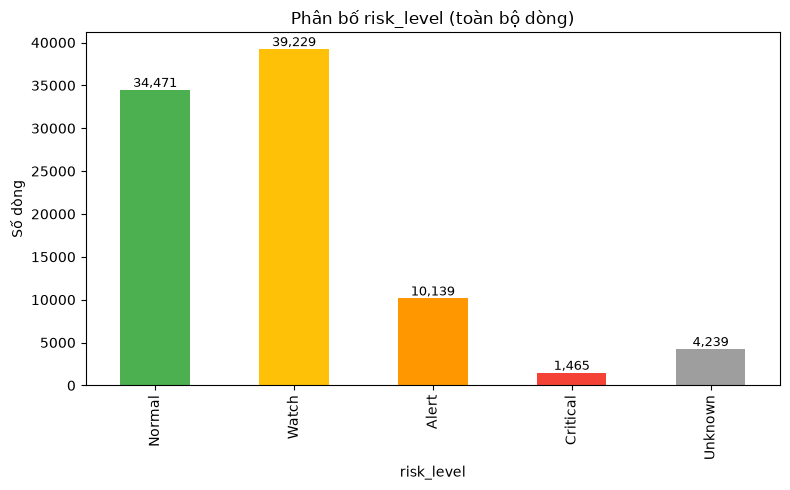

In [25]:
import matplotlib.pyplot as plt

order = ["Normal", "Watch", "Alert", "Critical", "Unknown"]
counts = label_df["risk_level"].value_counts().reindex(order).fillna(0)

fig, ax = plt.subplots(figsize=(8, 5))
counts.plot(kind="bar", ax=ax, color=["#4CAF50", "#FFC107", "#FF9800", "#F44336", "#9E9E9E"])
ax.set_title("Phân bố risk_level (toàn bộ dòng)")
ax.set_ylabel("Số dòng")
for i, v in enumerate(counts):
    ax.text(i, v, f"{int(v):,}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

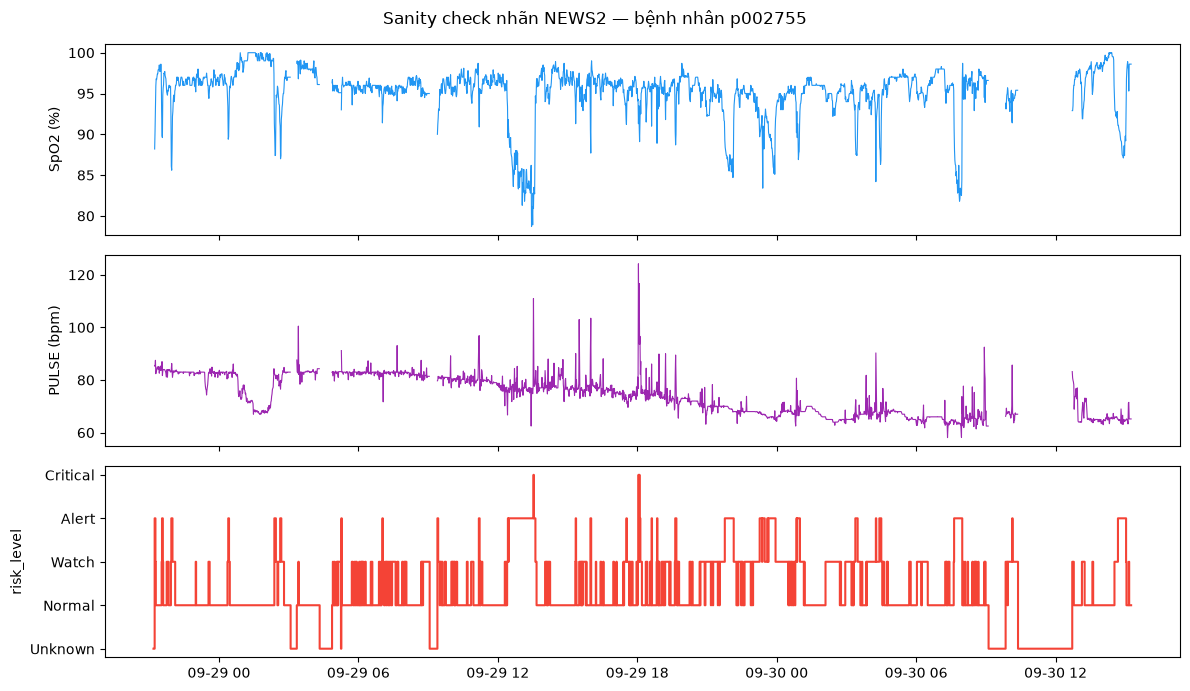

In [26]:
sample_patient = (
    label_df[label_df["risk_level"] != "Unknown"]
    .groupby("patient_id")["risk_level"].nunique()
    .sort_values(ascending=False)
    .index[0]
)
sample_df = label_df[label_df["patient_id"] == sample_patient].sort_values("timestamp")

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)

axes[0].plot(sample_df["timestamp"], sample_df["SPO2"], color="#2196F3", linewidth=0.8)
axes[0].set_ylabel("SpO2 (%)")

axes[1].plot(sample_df["timestamp"], sample_df["PULSE"], color="#9C27B0", linewidth=0.8)
axes[1].set_ylabel("PULSE (bpm)")

risk_map = {"Normal": 0, "Watch": 1, "Alert": 2, "Critical": 3, "Unknown": -1}
axes[2].step(sample_df["timestamp"], sample_df["risk_level"].map(risk_map), where="post", color="#F44336")
axes[2].set_yticks(list(risk_map.values()))
axes[2].set_yticklabels(list(risk_map.keys()))
axes[2].set_ylabel("risk_level")

fig.suptitle(f"Sanity check nhãn NEWS2 — bệnh nhân {sample_patient}")
plt.tight_layout()
plt.show()